# Hands-on Vision-Language-Action Models

Notebook ini membuat **Mini-VLA**.

Input:

```text
Image + Language Instruction
```

Output:

```text
Target Workspace Cell + Gripper Command
```

Mini-VLA ini bersifat edukasional agar pipeline VLA dapat dipelajari tanpa melatih foundation model besar.


## 1. Setup

Gunakan Google Colab GPU jika tersedia:

```text
Runtime → Change runtime type → GPU
```

Mini-VLA ini ringan dan umumnya aman pada T4.


In [ ]:
!pip -q install numpy matplotlib torch


## 2. Hubungkan Google Drive dan Tentukan Folder Project

Google Colab selalu mulai dari `/content`, meskipun notebook dibuka dari Google Drive.

Notebook ini **tidak melakukan pencarian rekursif ke seluruh Google Drive**. Cukup isi `PROJECT_DIR` dengan path folder `Vision-Language-Action Models` kamu.


In [ ]:
# Mount Google Drive.
from google.colab import drive

drive.mount(
    "/content/drive"
)

# Import library.
import os
import sys
from pathlib import Path

# ============================================================
# UBAH HANYA PATH INI.
# Copy path folder "Vision-Language-Action Models" dari panel
# Files Google Colab, lalu paste di sini.
# ============================================================
VLA_ROOT_DIR = Path(
    "/content/drive/MyDrive/00. Artificial Intelligence (AI)/"
    "Mengenal Embodied AI: Dari Teori, Simulasi hingga Robot Nyata/"
    "Bagian 4 — Bagaimana Robot Mengambil Keputusan?/"
    "Handson/Vision-Language-Action Models"
)

PROJECT_DIR = VLA_ROOT_DIR

# File utama yang harus tersedia.
required_files = [
    "generate_dataset.py",
    "vla_model.py",
    "train_vla.py",
    "evaluate_vla.py",
]

# Cek folder project.
if not PROJECT_DIR.exists():
    raise FileNotFoundError(
        "Project directory not found:\n"
        f"{PROJECT_DIR}\n\n"
        "Copy the folder path from the Colab Files panel "
        "and update PROJECT_DIR."
    )

# Cek file utama.
missing_files = [
    filename
    for filename in required_files
    if not (PROJECT_DIR / filename).exists()
]

if missing_files:
    raise FileNotFoundError(
        "The following project files are missing:\n"
        + "\n".join(
            f"- {filename}"
            for filename in missing_files
        )
    )

# Pindah ke folder project.
os.chdir(
    PROJECT_DIR
)

# Tambahkan folder project ke Python import path.
project_path = str(
    PROJECT_DIR
)

if project_path not in sys.path:
    sys.path.insert(
        0,
        project_path,
    )

print(
    "Project directory:",
    PROJECT_DIR,
)

print(
    "Current working directory:",
    Path.cwd(),
)

print(
    "\nProject setup completed."
)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project directory: /content/drive/MyDrive/00. Artificial Intelligence (AI)/Mengenal Embodied AI: Dari Teori, Simulasi hingga Robot Nyata/Bagian 4 — Bagaimana Robot Mengambil Keputusan?/Handson/Vision-Language-Action Models
Current working directory: /content/drive/MyDrive/00. Artificial Intelligence (AI)/Mengenal Embodied AI: Dari Teori, Simulasi hingga Robot Nyata/Bagian 4 — Bagaimana Robot Mengambil Keputusan?/Handson/Vision-Language-Action Models

Project setup completed.


## 3. Verifikasi File Project

Cell berikut hanya mengecek file pada folder project yang sudah dipilih. Tidak ada scanning ke folder Google Drive lain.


In [ ]:
# Menampilkan file utama.
print(
    "Required files:"
)

for filename in [
    "generate_dataset.py",
    "vla_model.py",
    "train_vla.py",
    "evaluate_vla.py",
]:
    print(
        f"- {filename}: OK"
    )

# Verifikasi import lokal.
from vla_model import MiniVLA

print(
    "\nLocal import successful: vla_model.MiniVLA"
)


Required files:
- generate_dataset.py: OK
- vla_model.py: OK
- train_vla.py: OK
- evaluate_vla.py: OK

Local import successful: vla_model.MiniVLA


## 4. Generate Demonstration Data

Dataset memiliki satu colored target block, beberapa gray distractors, dan natural-language instruction.


In [ ]:
!python generate_dataset.py


Synthetic VLA dataset created.
Training samples: 1800
Testing samples: 400
Training dataset saved to: /content/drive/MyDrive/00. Artificial Intelligence (AI)/Mengenal Embodied AI: Dari Teori, Simulasi hingga Robot Nyata/Bagian 4 — Bagaimana Robot Mengambil Keputusan?/Handson/Vision-Language-Action Models/results/train_vla.npz
Testing dataset saved to: /content/drive/MyDrive/00. Artificial Intelligence (AI)/Mengenal Embodied AI: Dari Teori, Simulasi hingga Robot Nyata/Bagian 4 — Bagaimana Robot Mengambil Keputusan?/Handson/Vision-Language-Action Models/results/test_vla.npz


## 5. Lihat Arsitektur Mini-VLA

Model terdiri dari:

```text
Vision Encoder
Language Encoder
Language-Conditioned Visual Attention
Multimodal Fusion
Action Heads
```


In [ ]:
from vla_model import MiniVLA

model = MiniVLA()

print(model)


MiniVLA(
  (vision_encoder): Sequential(
    (0): Conv2d(3, 16, kernel_size=(5, 5), stride=(2, 2), padding=(2, 2))
    (1): ReLU()
    (2): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (5): ReLU()
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Linear(in_features=4096, out_features=256, bias=True)
    (8): ReLU()
  )
  (token_embedding): Embedding(9, 32, padding_idx=0)
  (language_projection): Sequential(
    (0): Linear(in_features=32, out_features=64, bias=True)
    (1): ReLU()
  )
  (fusion): Sequential(
    (0): Linear(in_features=320, out_features=192, bias=True)
    (1): ReLU()
    (2): Linear(in_features=192, out_features=96, bias=True)
    (3): ReLU()
  )
  (cell_head): Linear(in_features=96, out_features=9, bias=True)
  (gripper_head): Linear(in_features=96, out_features=1, bias=True)
)


## 6. Training

Training belajar mapping:

```text
(image, instruction) -> action
```


In [ ]:
!python train_vla.py


Epoch 01 | Loss: 2.46241
Epoch 02 | Loss: 0.69045
Epoch 03 | Loss: 0.00636
Epoch 04 | Loss: 0.00057
Epoch 05 | Loss: 0.00030
Epoch 06 | Loss: 0.00020
Epoch 07 | Loss: 0.00015
Epoch 08 | Loss: 0.00011
Epoch 09 | Loss: 0.00008
Epoch 10 | Loss: 0.00006
Epoch 11 | Loss: 0.00005
Epoch 12 | Loss: 0.00004
Epoch 13 | Loss: 0.00003
Epoch 14 | Loss: 0.00003
Epoch 15 | Loss: 0.00002

Training completed.
Device: cuda
Model saved to: /content/drive/MyDrive/00. Artificial Intelligence (AI)/Mengenal Embodied AI: Dari Teori, Simulasi hingga Robot Nyata/Bagian 4 — Bagaimana Robot Mengambil Keputusan?/Handson/Vision-Language-Action Models/results/mini_vla.pt
Training history saved to: /content/drive/MyDrive/00. Artificial Intelligence (AI)/Mengenal Embodied AI: Dari Teori, Simulasi hingga Robot Nyata/Bagian 4 — Bagaimana Robot Mengambil Keputusan?/Handson/Vision-Language-Action Models/results/training_history.npz
Training plot saved to: /content/drive/MyDrive/00. Artificial Intelligence (AI)/Mengenal Em

## 7. Evaluation


In [ ]:
!python evaluate_vla.py


Target-cell accuracy: 100.00%
Gripper accuracy: 100.00%
Evaluation metrics saved to: /content/drive/MyDrive/00. Artificial Intelligence (AI)/Mengenal Embodied AI: Dari Teori, Simulasi hingga Robot Nyata/Bagian 4 — Bagaimana Robot Mengambil Keputusan?/Handson/Vision-Language-Action Models/results/evaluation_metrics.txt
Evaluation figure saved to: /content/drive/MyDrive/00. Artificial Intelligence (AI)/Mengenal Embodied AI: Dari Teori, Simulasi hingga Robot Nyata/Bagian 4 — Bagaimana Robot Mengambil Keputusan?/Handson/Vision-Language-Action Models/results/evaluation_result.png
Figure(800x800)


## 8. Tampilkan Hasil


Training loss result:


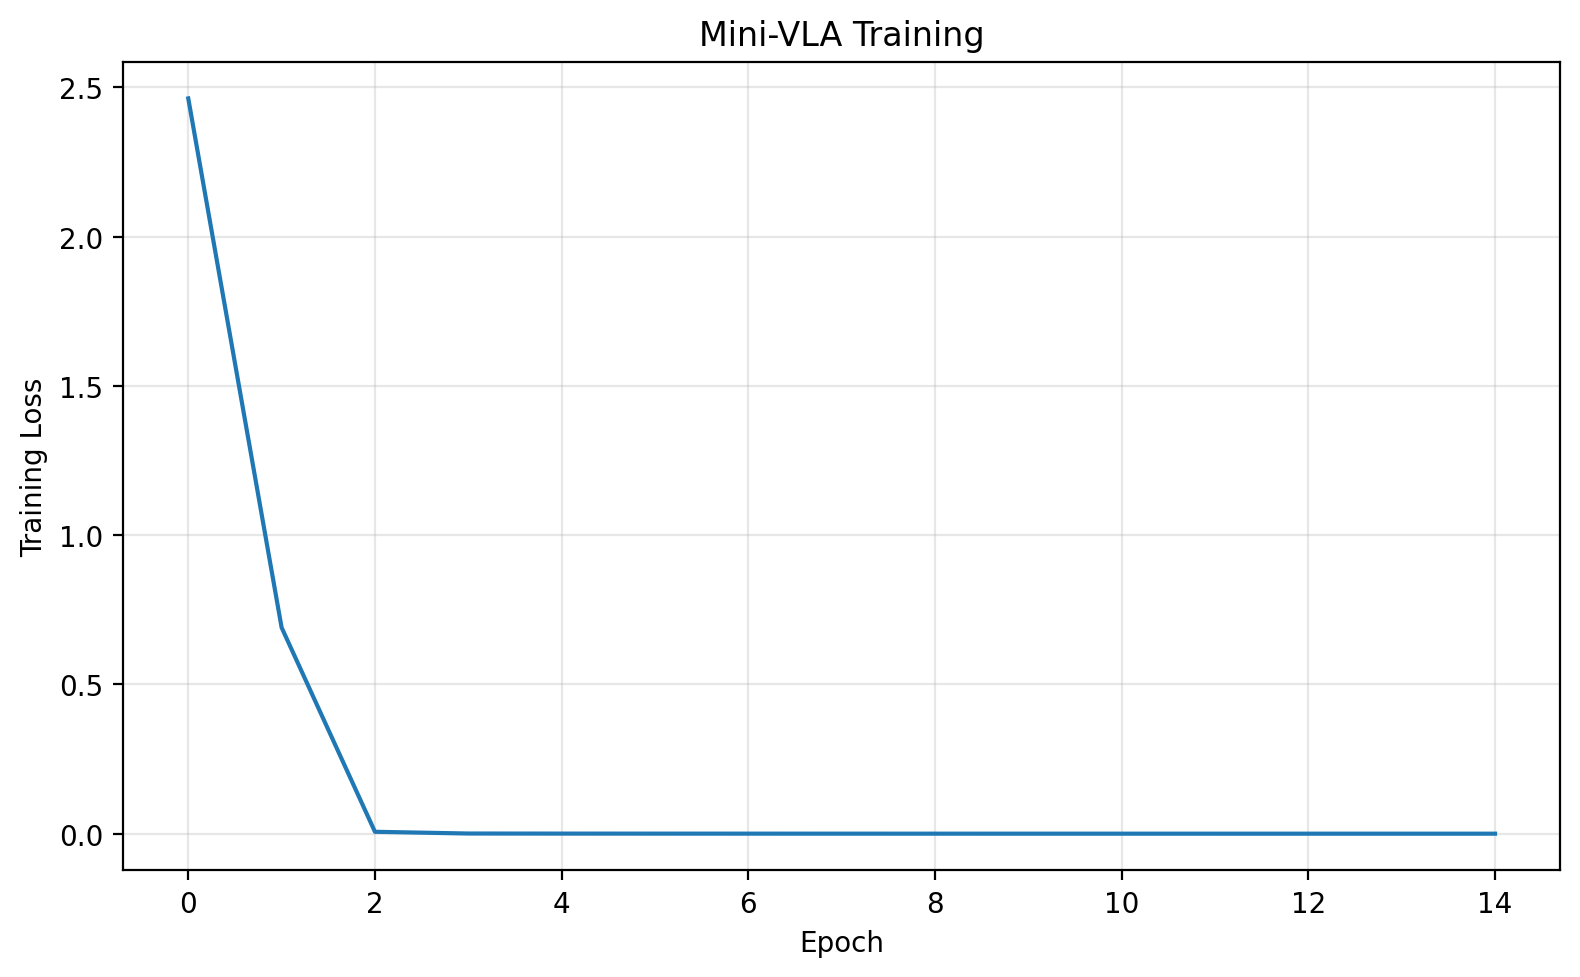

Evaluation result:


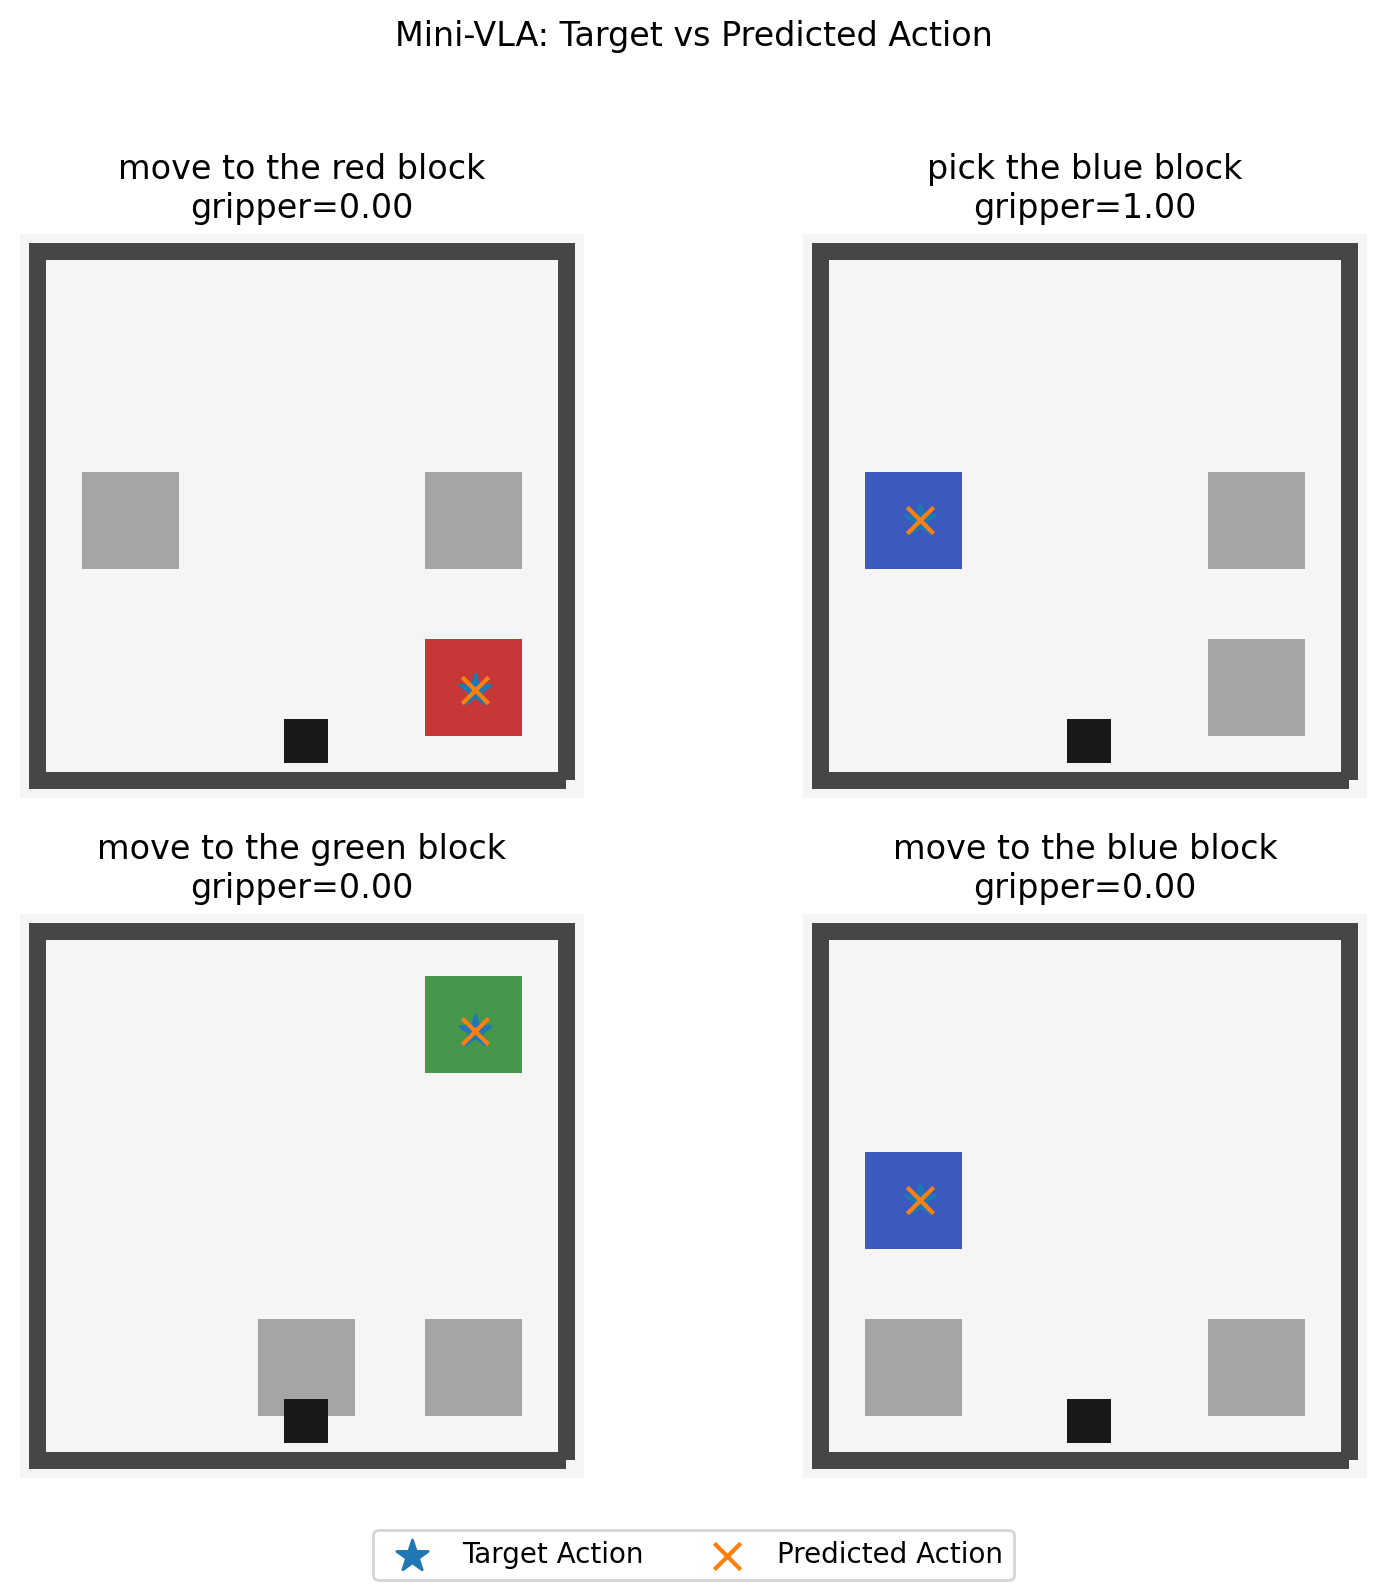

Results loaded from: results/


In [ ]:
# Menampilkan dua hasil utama dari Mini-VLA.
from IPython.display import Image, display

print(
    "Training loss result:"
)

display(
    Image(
        filename="results/training_loss.png"
    )
)

print(
    "Evaluation result:"
)

display(
    Image(
        filename="results/evaluation_result.png"
    )
)

print(
    "Results loaded from: results/"
)


## 9. Interpretasi

Mini-VLA langsung menghasilkan action representation dari vision dan language.

Pada VLA modern, backbone dan dataset jauh lebih besar dan output sering berupa **continuous action chunks** untuk robot nyata.
